# Normalise logRR curves to TMREL

To normalise the logRR: `logRR - logRR.sel(daily_temperature=tmrel_mean)` shape:(annual_temperature, daily_temperature, draws)  
This doesn't take into consideration the uncertainty in the tmrel -> mostly because there are 100 draws for tmrel and 1000 draws for logRR -> could figure out how to adjust for that to include that uncertainty but it would be different to the Burkhart paper.  
This method does create a "pinched" confidence interval, if I instead perform `logRR.quantile("draws", XX) - logRR.mean("draws").sel(daily_temperature=tmrel_mean)` shape:(annual_temperature, daily_temperature) the confidence interval is no longer "pinched".

In [1]:
import os
import numpy as np
import xarray as xr
import json
import pathlib
import config
from utils.utils import require_dir
import warnings
import matplotlib.pyplot as plt

In [2]:
# === Setup ===
DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "GBD23")
RR_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "GBD23" / "RR_curves" / "temperature")
TMREL_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "GBD23" / "TMREL")
TMREL_SUM_DIR = require_dir(pathlib.Path(config.WORK_ROOT) / "GBD23" / "TMREL" / "summaries")

# Load look up file
lookup_file = "country_location_ids.json"  # {"Armenia": 33, "Azerbaijan": 34, ...}
lookup_path = os.path.join(DIR, lookup_file)
with open(lookup_path, "r", encoding="utf-8") as f:
    country_to_id = json.load(f)

In [3]:
health_var = ["CHRONIC_KIDNEY_DISEASE", "CARDIOMYOPATHY_MYOCARDITIS",
              "HYPERTENSIVE_HEART_DISEASE", "ISCHEMIC_HEART_DISEASE",
              "STROKE", "DIABETES", "INJ_ANIMAL", "INJ_DISASTER",
              "DROWNING", "HOMICIDE", "MECHANICAL_INJ",
              "OTHER_UNINTENTIONAL_INJ", "SUICIDE", "OTHER_TRANSPORT_INJ",
              "ROAD_TRANSPORT_INJ", "LOWER_RESPIRATORY_INFECTIONS", "COPD"]

In [4]:
logrr_file = "STROKE_logRR_curve_samples.nc"
logrr_path = os.path.join(RR_DIR, logrr_file)
logRR = xr.open_dataarray(logrr_path)

### Data with draws

In [18]:
tmrel_ex_file = "global_tmrel.nc"
tmrel_ex_path = os.path.join(TMREL_DIR, tmrel_ex_file)
tmrel_da = xr.open_dataarray(tmrel_ex_path)

### Data with summary stats

In [6]:
tmrel_ex_file = "global_tmrel_summaries.nc"
tmrel_ex_path = os.path.join(TMREL_SUM_DIR, tmrel_ex_file)
tmrel_ds = xr.open_dataset(tmrel_ex_path)
tmrelMean = tmrel_ds["tmrelMean"]
tmrelLower = tmrel_ds["tmrelLower"]
tmrelUpper = tmrel_ds["tmrelUpper"]

### 1. Following the method of Burkhart et al., 2021

`logRR - logRR.sel(daily_temperature=tmrel_mean)` shape:(annual_temperature, daily_temperature, draws)  

In [7]:
def normalize_to_tmrel(logrr: xr.DataArray, tmrelMean: xr.DataArray):
    """
    R equivalent:
        rrClean[, refRR := sum(rrMean * (dailyTempCat==tmrel)), by=meanTempCat]
        rrClean[refRR==0, refRR := sum(rrMean * (dailyTempCat==(tmrel+1))), by=meanTempCat]
        rrClean[, rrMean := rrMean/refRR]

    R rounded tmrel onto the same integer grid as dailyTempCat and matched with
    `==`, with a "+1 bin" fallback if that landed on a gap. Here daily_temperature
    is already a fine (0.1-degree) continuous grid, so selecting the nearest grid
    point is the direct equivalent and needs no separate fallback step.
    """
    ref_logRR = logrr.sel(daily_temperature=tmrelMean, method="nearest")  # dims: annual_temperature, draws
    logrr_normalized = logrr - ref_logRR  # broadcasts over daily_temperature
    return logrr_normalized, ref_logRR

In [8]:
logrr_normalized, refRR = normalize_to_tmrel(logRR, tmrelMean)

# sanity check: logRR should be ~0 at TMREL for every zone/draw
check = logrr_normalized.sel(daily_temperature=tmrelMean, method="nearest")
assert np.allclose(check.values, 0), "logRR at TMREL should be exactly 0 after normalization"
print("Sanity check passed: logRR == 0 at TMREL for all zones/draws.")

Sanity check passed: logRR == 0 at TMREL for all zones/draws.


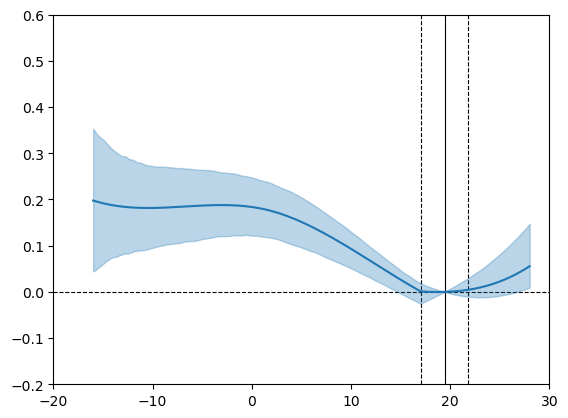

In [9]:
rr_slice = logrr_normalized.sel(annual_temperature=10)
tmrel_mean = tmrelMean.sel(annual_temperature=10)
tmrel_lower = tmrelLower.sel(annual_temperature=10)
tmrel_upper = tmrelUpper.sel(annual_temperature=10)

mean_curve = rr_slice.mean("draws")
x_dim = mean_curve.dims[0]
x = mean_curve[x_dim].values

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered")
    lower = rr_slice.quantile(0.025, dim="draws")
    upper = rr_slice.quantile(0.975, dim="draws")

fig, ax = plt.subplots()

ax.plot(x, mean_curve.values, color="C0", lw=1.5)
ax.fill_between(x, lower.values, upper.values, color="C0", alpha=0.3)
ax.axhline(0, color="black", lw=0.8, linestyle="--", zorder=0)
ax.axvline(tmrel_mean, color="black", lw=0.8, zorder=0)
ax.axvline(tmrel_lower, color="black", lw=0.8, linestyle="--", zorder=0)
ax.axvline(tmrel_upper, color="black", lw=0.8, linestyle="--", zorder=0)

ax.set_ylim([-0.2, 0.6])
ax.set_xlim([-20, 30])

plt.show()

### 2. Alternative method

`logRR.quantile(XX, "draws") - logRR.mean("draws").sel(daily_temperature=tmrel_mean)` shape:(annual_temperature, daily_temperature) 

In [10]:
def normalize_curve_to_tmrel(logRR: xr.DataArray, tmrel_mean: xr.DataArray):
    """
    Parameters
    ----------
    logRR : DataArray, dims (annual_temperature, daily_temperature, draws)
        Raw log-RR draws, as saved by 0__Save_logRR_curves_GBD.ipynb.
    tmrel_mean : DataArray, dims (annual_temperature,)
        e.g. tmrel_ds["tmrelMean"] from 0__Save_TMREL_summaries_GBD.ipynb.

    Returns
    -------
    xr.Dataset with variables logRR_mean, logRR_lower, logRR_upper and
    RR_mean, RR_lower, RR_upper, each dims (annual_temperature, daily_temperature).
    """
    # summary stats from RAW draws -- order matters, this must happen first
    mean_raw = logRR.mean(dim="draws")
    lower_raw = logRR.quantile(0.025, dim="draws").drop_vars("quantile")
    upper_raw = logRR.quantile(0.975, dim="draws").drop_vars("quantile")

    # single scalar per zone: the MEAN's value at TMREL (not each draw's)
    ref = mean_raw.sel(daily_temperature=tmrel_mean, method="nearest")

    logRR_mean = mean_raw - ref
    logRR_lower = lower_raw - ref
    logRR_upper = upper_raw - ref

    return xr.Dataset({
        "logRR_mean": logRR_mean, "logRR_lower": logRR_lower, "logRR_upper": logRR_upper,
        "RR_mean": np.exp(logRR_mean), "RR_lower": np.exp(logRR_lower), "RR_upper": np.exp(logRR_upper),
    })

In [11]:
curves = normalize_curve_to_tmrel(logRR, tmrelMean)
logRR_mean = curves["logRR_mean"]
logRR_lower = curves["logRR_lower"]
logRR_upper = curves["logRR_upper"]

# sanity check: RR should be ~1.0 at TMREL for every zone/draw
check = logRR_mean.sel(daily_temperature=tmrelMean, method="nearest")
assert np.allclose(check.values, 0), "logRR at TMREL should be exactly 0 after normalization"
print("Sanity check passed: logRR == 0 at TMREL for all zones/draws.")

/glade/work/awells/conda-envs/my-env/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Sanity check passed: logRR == 0 at TMREL for all zones/draws.


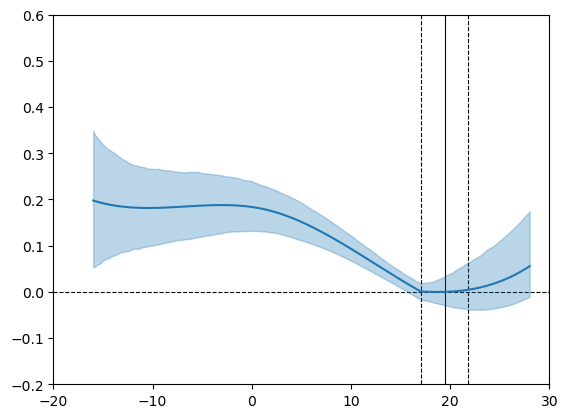

In [12]:
rr_slice = logRR_mean.sel(annual_temperature=10)
tmrel_mean = tmrelMean.sel(annual_temperature=10)
tmrel_lower = tmrelLower.sel(annual_temperature=10)
tmrel_upper = tmrelUpper.sel(annual_temperature=10)

mean_curve = rr_slice
x_dim = mean_curve.dims[0]
x = mean_curve[x_dim].values

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered")
    lower = logRR_lower.sel(annual_temperature=10)
    upper = logRR_upper.sel(annual_temperature=10)

fig, ax = plt.subplots()

ax.plot(x, mean_curve.values, color="C0", lw=1.5)
ax.fill_between(x, lower.values, upper.values, color="C0", alpha=0.3)
ax.axhline(0, color="black", lw=0.8, linestyle="--", zorder=0)
ax.axvline(tmrel_mean, color="black", lw=0.8, zorder=0)
ax.axvline(tmrel_lower, color="black", lw=0.8, linestyle="--", zorder=0)
ax.axvline(tmrel_upper, color="black", lw=0.8, linestyle="--", zorder=0)

ax.set_ylim([-0.2, 0.6])
ax.set_xlim([-20, 30])

plt.show()

### 3. Third method

Instead of taking `logRR - logRR.sel(daily_temperature=tmrel_mean)` and not including the uncertainty in the tmrel, resample the tmrel draws from 100 -> 1000 and take `logRR - logRR.sel(daily_temperature=tmrel)` shape:(annual_temperature, daily_temperature, draws)

In [13]:
def resample_tmrel(tmrel, n_logRR_draws):
    n_tmrel_draws = tmrel.sizes["draws"]
    # Resample TMREL draws (with replacement) to match logRR's draw count
    rng = np.random.default_rng(42)  # fixed seed: reproducible
    resample_idx = rng.integers(0, n_tmrel_draws, size=n_logRR_draws)

    tmrel_new_draws = tmrel.isel(draws=resample_idx)
    # re-label draws 0..999 so it aligns positionally with logRR's draws dim
    tmrel_new_draws = tmrel_new_draws.assign_coords(draws=np.arange(n_logRR_draws))
    return tmrel_new_draws

In [14]:
def normalize_to_tmrel(logrr: xr.DataArray, tmrel: xr.DataArray):
    """
    normalize with all tmrel draws to include tmrel uncertainty
    """
    ref_logRR = logrr.sel(daily_temperature=tmrel, method="nearest")  # dims: annual_temperature, draws
    logrr_normalized = logrr - ref_logRR  # broadcasts over daily_temperature
    return logrr_normalized, ref_logRR

In [30]:
n_logRR_draws = logRR.sizes["draws"]
tmrel_extra_draws = resample_tmrel(tmrel_da, n_logRR_draws)

tmrelMean = tmrel_extra_draws.mean("draws")
tmrelLower = tmrel_extra_draws.quantile(0.025, "draws")
tmrelUpper = tmrel_extra_draws.quantile(0.975, "draws")

In [22]:
logrr_normalized, refRR = normalize_to_tmrel(logRR, tmrel_extra_draws)

# sanity check: logRR should be ~0 at TMREL for every zone/draw
check = logrr_normalized.sel(daily_temperature=tmrelMean, method="nearest")
assert np.allclose(check.values, 0), "logRR at TMREL should be exactly 0 after normalization"
print("Sanity check passed: logRR == 0 at TMREL for all zones/draws.")

AssertionError: logRR at TMREL should be exactly 0 after normalization

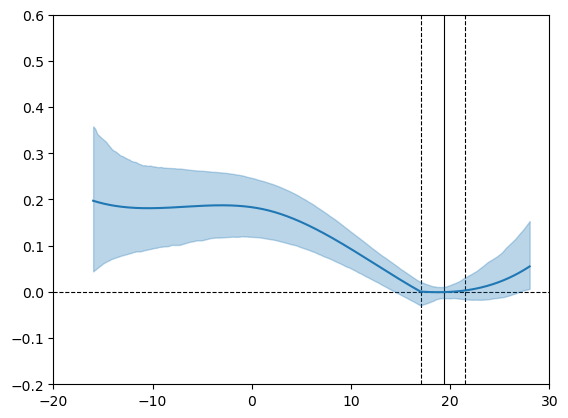

In [31]:
rr_slice = logrr_normalized.sel(annual_temperature=10)
tmrel_mean = tmrelMean.sel(annual_temperature=10)
tmrel_lower = tmrelLower.sel(annual_temperature=10)
tmrel_upper = tmrelUpper.sel(annual_temperature=10)

mean_curve = rr_slice.mean("draws")
x_dim = mean_curve.dims[0]
x = mean_curve[x_dim].values

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="All-NaN slice encountered")
    lower = rr_slice.quantile(0.025, dim="draws")
    upper = rr_slice.quantile(0.975, dim="draws")

fig, ax = plt.subplots()

ax.plot(x, mean_curve.values, color="C0", lw=1.5)
ax.fill_between(x, lower.values, upper.values, color="C0", alpha=0.3)
ax.axhline(0, color="black", lw=0.8, linestyle="--", zorder=0)
ax.axvline(tmrel_mean, color="black", lw=0.8, zorder=0)
ax.axvline(tmrel_lower, color="black", lw=0.8, linestyle="--", zorder=0)
ax.axvline(tmrel_upper, color="black", lw=0.8, linestyle="--", zorder=0)

ax.set_ylim([-0.2, 0.6])
ax.set_xlim([-20, 30])

plt.show()